# Step 2: Data Alignment and Preprocessing

**Objective:** Load the catalog, extract 1D spectra from SDSS mwmStar FITS files, resample them onto a common **logarithmic** wavelength grid, normalise, export the master HDF5 tensor, and tag every spectrum with its train/validation/test partition.

Outputs used downstream: `data/sdss_tensors.h5` (the spectra, row *i* aligned with row *i* of the catalogue), `data/sdss_final_catalog.csv` (with the `dataset_split` column) and `data/preprocessing_meta.json` (scaler constants and grid). The label-noise floor stays in `data/catalog_meta.json`, written by Step 1.

**Why a logarithmic grid.** SDSS stores spectra on a grid of constant `dlog10(lambda) = 1e-4`, because the spectrograph's resolving power `R` is approximately constant, so the narrowest recordable feature has a width proportional to `lambda`. Resampling onto a *linear* grid therefore discards native pixels blueward of ~7100 A and invents pixels redward of it. On a 4096-point linear grid over [3600, 10300] A the Balmer series, Ca II H&K and Mg b all fall below the Nyquist limit of 2 pixels per resolution element. A log grid with the same 4096 points keeps ~1.95 pixels per resolution element uniformly across the range, only 11% coarser than the native sampling.

A second consequence matters for the perturbation experiments of Step 5: on a log grid a uniform pixel shift is a constant-*velocity* shift (1 pixel = 77.0 km/s everywhere), i.e. a genuine radial-velocity offset. On a linear grid the same operation is a constant-*wavelength* shift, which is a wavelength-calibration error instead, and corresponds to 136 km/s at the blue end but only 48 km/s at the red end.

In [1]:
import os
import json
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.size': 12,
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'stix',
})

# ==========================================
# 1. PATH AND GRID CONFIGURATION
# ==========================================
root_dir = 'data/fits_files/'
catalog_path = 'data/sdss_catalog.csv'

UNIVERSAL_START = 3600.0
UNIVERSAL_END = 10300.0
SEQ_LENGTH = 4096
MIN_VALID_FRAC = 0.80     # reject a spectrum if fewer than 80% of grid pixels are usable

# --- per-pixel quality criteria ----------------------------------------------
USE_IVAR = True
USE_PIXEL_FLAGS = False

# Bits that indicate an unusable pixel, should flag filtering be enabled.
# Names follow the BOSS SPPIXMASK convention.
SERIOUS_FLAG_BITS = [0, 1, 2, 3, 4, 5, 6, 7, 18, 22, 23, 24, 28]
SERIOUS_FLAG_MASK = sum(1 << b for b in SERIOUS_FLAG_BITS)   # 0x11C400FF

# Logarithmic grid: constant dlog10(lambda), matching the SDSS native convention
standard_wave = np.logspace(np.log10(UNIVERSAL_START), np.log10(UNIVERSAL_END), SEQ_LENGTH)
DLOG10 = np.log10(UNIVERSAL_END / UNIVERSAL_START) / (SEQ_LENGTH - 1)

print("Wavelength grid")
print(f"  range        : {UNIVERSAL_START:.1f} - {UNIVERSAL_END:.1f} A")
print(f"  n_pixels     : {SEQ_LENGTH}")
print(f"  dlog10       : {DLOG10:.6e}  (SDSS native: 1.0e-04, "
      f"{DLOG10/1e-4:.3f}x coarser)")
print(f"  dlambda      : {np.diff(standard_wave).min():.3f} A (blue) -> "
      f"{np.diff(standard_wave).max():.3f} A (red)")
print(f"  1 pixel      : {299792.458 * np.log(10) * DLOG10:.1f} km/s "
      f"at every wavelength")
print(f"\nPixel quality: ivar>0 {'ON' if USE_IVAR else 'OFF'}, "
      f"pixel_flags {'ON (mask 0x%08X)' % SERIOUS_FLAG_MASK if USE_PIXEL_FLAGS else 'OFF'}")

# ==========================================
# 2. LOAD CATALOG AND STEP-1 METADATA
# ==========================================
golden_df = pd.read_csv(catalog_path)
print(f"\nLoaded {len(golden_df):,} target records from the golden catalog.")
print(f"  Teff range   : {golden_df['teff'].min():.2f} - "
      f"{golden_df['teff'].max():.2f} K")
print(f"  columns      : {golden_df.columns.tolist()}")

# ==========================================
# 3. FITS EXTRACTION ENGINE
# ==========================================
def get_sdss_filename(row, root_dir):
    """Construct the mwmStar filename from the sdss_id."""
    return os.path.join(root_dir, f"mwmStar-0.6.0-{row['sdss_id']}.fits")

def read_sdss_spectrum(filepath, want_quality=True):
    """
    Read wavelength, flux and (when present) the per-pixel quality arrays from
    an SDSS mwmStar file. HDU 1 is the APO/BOSS coadd, HDU 2 the LCO one.

    Returns (wave, flux, ivar, pixel_flags); ivar / pixel_flags are None when
    the file does not carry them.
    """
    try:
        with fits.open(filepath) as hdul:
            hdu_idx = -1
            if len(hdul) > 1 and hdul[1].header.get('NAXIS2', 0) > 0:
                hdu_idx = 1
            elif len(hdul) > 2 and hdul[2].header.get('NAXIS2', 0) > 0:
                hdu_idx = 2
            if hdu_idx == -1:
                return None, None, None, None

            data = hdul[hdu_idx].data
            cols = [c.lower() for c in data.columns.names]
            wave = np.asarray(data['wavelength'][0], dtype=np.float64)
            flux = np.asarray(data['flux'][0], dtype=np.float64)

            ivar = flags = None
            if want_quality:
                if 'ivar' in cols:
                    ivar = np.asarray(
                        data[data.columns.names[cols.index('ivar')]][0],
                        dtype=np.float64)
                for cand in ('pixel_flags', 'and_mask', 'or_mask'):
                    if cand in cols:
                        flags = np.asarray(
                            data[data.columns.names[cols.index(cand)]][0])
                        break
            return wave, flux, ivar, flags
    except Exception:
        return None, None, None, None

# ==========================================
# 4. INSPECT ONE FILE - what quality columns exist?
# ==========================================
probe = get_sdss_filename(golden_df.iloc[0], root_dir)
if os.path.exists(probe):
    with fits.open(probe) as hdul:
        print(f"\nStructure of {os.path.basename(probe)}:")
        for j, hdu in enumerate(hdul):
            n = hdu.header.get('NAXIS2', 0)
            cn = list(hdu.columns.names) if getattr(hdu, 'columns', None) else []
            print(f"  HDU {j}: NAXIS2={n}  columns={cn}")
else:
    print(f"\n[warn] probe file not found: {probe}")

print("\nSetup complete. FITS reading engine is ready.")

Wavelength grid
  range        : 3600.0 - 10300.0 A
  n_pixels     : 4096
  dlog10       : 1.114859e-04  (SDSS native: 1.0e-04, 1.115x coarser)
  dlambda      : 0.924 A (blue) -> 2.644 A (red)
  1 pixel      : 77.0 km/s at every wavelength

Pixel quality: ivar>0 ON, pixel_flags OFF

Loaded 188,979 target records from the golden catalog.
  Teff range   : 3500.02 - 8999.28 K
  columns      : ['catalogid', 'sdss_id', 'pipeline', 'teff', 'e_teff', 'logg', 'snr']

Structure of mwmStar-0.6.0-55234278.fits:
  HDU 0: NAXIS2=0  columns=[]
  HDU 1: NAXIS2=1  columns=['spectrum_pk_id', 'release', 'filetype', 'v_astra', 'healpix', 'sdss_id', 'run2d', 'telescope', 'min_mjd', 'max_mjd', 'n_visits', 'n_good_visits', 'n_good_rvs', 'v_rad', 'e_v_rad', 'std_v_rad', 'median_e_v_rad', 'xcsao_teff', 'xcsao_e_teff', 'xcsao_logg', 'xcsao_e_logg', 'xcsao_fe_h', 'xcsao_e_fe_h', 'xcsao_meanrxc', 'snr', 'gri_gaia_transform_flags', 'zwarning_flags', 'wavelength', 'flux', 'ivar', 'pixel_flags', 'continuum', 'nmf_r

## 2.1 Parallel wavelength-boundary survey

A parallel scan over every FITS file, establishing the wavelength interval common to all spectra and verifying that the native grid really is logarithmic. The latter check matters because the whole rationale for the target grid rests on it.

In [2]:
import concurrent.futures

print("Initiating parallel wavelength-boundary survey...")

def scan_single_file(row_series):
    """Return (min_wave, max_wave, n_pix, dlog10_mean, dlog10_spread) for one file."""
    filepath = get_sdss_filename(row_series, root_dir)
    if not os.path.exists(filepath):
        return None
    wave, _, _, _ = read_sdss_spectrum(filepath, want_quality=False)
    if wave is None or len(wave) < 10:
        return None
    lg = np.log10(wave)
    d = np.diff(lg)
    return wave.min(), wave.max(), len(wave), d.mean(), d.std() / d.mean()

max_threads = min(32, (os.cpu_count() or 1) * 4)
print(f"Deploying {max_threads} parallel threads...\n")

records = []
with concurrent.futures.ThreadPoolExecutor(max_workers=max_threads) as executor:
    futures = [executor.submit(scan_single_file, row)
               for _, row in golden_df.iterrows()]
    for fut in tqdm(concurrent.futures.as_completed(futures),
                    total=len(golden_df), desc="Scanning"):
        r = fut.result()
        if r is not None:
            records.append(r)

if not records:
    raise RuntimeError("No spectra could be read. Check root_dir and file integrity.")

arr = np.array(records)
mins, maxs, npix, dlogs, spreads = arr[:, 0], arr[:, 1], arr[:, 2], arr[:, 3], arr[:, 4]

safe_start = mins.max()      # the reddest blue edge
safe_end = maxs.min()        # the bluest red edge

print("\n" + "=" * 62)
print("SURVEY COMPLETE")
print("=" * 62)
print(f"Files scanned          : {len(records):,} / {len(golden_df):,}")
print(f"Absolute minimum wave  : {mins.min():.2f} A")
print(f"Absolute maximum wave  : {maxs.max():.2f} A")
print("-" * 62)
print(f"Common interval start  : {safe_start:.2f} A")
print(f"Common interval end    : {safe_end:.2f} A")
print(f"Chosen grid            : {UNIVERSAL_START:.1f} - {UNIVERSAL_END:.1f} A")
inside = (safe_start <= UNIVERSAL_START) and (safe_end >= UNIVERSAL_END)
print(f"  -> chosen grid is {'INSIDE' if inside else 'NOT inside'} the common "
      f"interval; {'no extrapolation' if inside else 'EXTRAPOLATION WOULD OCCUR'}")

print("-" * 62)
print("Native grid verification")
print(f"  n_pixels            : {npix.min():.0f} - {npix.max():.0f} "
      f"(median {np.median(npix):.0f})")
print(f"  dlog10 across files : {dlogs.min():.6e} - {dlogs.max():.6e}")
print(f"  within-file spread  : median {np.median(spreads):.2e}")
print(f"  -> native sampling is {'LOG-uniform' if np.median(spreads) < 1e-2 else 'NOT log-uniform'}"
      f", dlog10 = {np.median(dlogs):.6e}")

n_native_in_range = np.log10(UNIVERSAL_END / UNIVERSAL_START) / np.median(dlogs)
print(f"  native pixels inside [{UNIVERSAL_START:.0f}, {UNIVERSAL_END:.0f}]: "
      f"{n_native_in_range:.0f}")
print(f"  target grid uses {SEQ_LENGTH} points "
      f"({100 * SEQ_LENGTH / n_native_in_range:.1f}% of the native count)")
print("=" * 62)

Initiating parallel wavelength-boundary survey...
Deploying 32 parallel threads...



Scanning: 100%|██████████| 188979/188979 [49:32<00:00, 63.57it/s]  



SURVEY COMPLETE
Files scanned          : 188,979 / 188,979
Absolute minimum wave  : 3566.97 A
Absolute maximum wave  : 10399.20 A
--------------------------------------------------------------
Common interval start  : 3566.97 A
Common interval end    : 10399.20 A
Chosen grid            : 3600.0 - 10300.0 A
  -> chosen grid is INSIDE the common interval; no extrapolation
--------------------------------------------------------------
Native grid verification
  n_pixels            : 4648 - 4648 (median 4648)
  dlog10 across files : 1.000000e-04 - 1.000000e-04
  within-file spread  : median 1.61e-04
  -> native sampling is LOG-uniform, dlog10 = 1.000000e-04
  native pixels inside [3600, 10300]: 4565
  target grid uses 4096 points (89.7% of the native count)


## 2.1b Pixel-quality audit

A short audit on a random sample of files, establishing how much of each spectrum each validity condition removes before the full run is launched. The cumulative columns show the surviving fraction after applying the conditions in sequence, so a large drop between two adjacent columns identifies the binding constraint.

The audit also decomposes `pixel_flags` into its constituent bits. The column is a bitmask rather than a boolean, and in the BOSS coadds the PARTIALREJECT bit is set on a large majority of pixels while carrying no implication that the pixel is unusable. Testing `flags == 0` would therefore discard most of the data.

In [3]:
N_PROBE = 30
probe_rows = golden_df.sample(min(N_PROBE, len(golden_df)), random_state=0)

rows, flag_hist = [], {}
for _, row in probe_rows.iterrows():
    fp = get_sdss_filename(row, root_dir)
    if not os.path.exists(fp):
        continue
    wave, flux, ivar, flags = read_sdss_spectrum(fp)
    if wave is None:
        continue

    in_range = (wave >= UNIVERSAL_START) & (wave <= UNIVERSAL_END)
    n = int(in_range.sum())
    if n == 0:
        continue

    c_fin = np.isfinite(flux) & in_range
    c_pos = c_fin & (flux > 0)
    c_ivar = c_pos & ((np.isfinite(ivar) & (ivar > 0)) if ivar is not None else True)
    if flags is not None:
        fi = np.asarray(flags, dtype=np.int64)
        c_zero = c_ivar & (fi == 0)
        c_serious = c_ivar & ((fi & SERIOUS_FLAG_MASK) == 0)
        for v, cnt in zip(*np.unique(fi[in_range], return_counts=True)):
            flag_hist[int(v)] = flag_hist.get(int(v), 0) + int(cnt)
    else:
        c_zero = c_serious = c_ivar

    rows.append({'n_in_range': n,
                 'finite': c_fin.sum() / n,
                 '+ flux>0': c_pos.sum() / n,
                 '+ ivar>0': c_ivar.sum() / n,
                 '+ flags==0': c_zero.sum() / n,
                 '+ serious bits': c_serious.sum() / n})

audit = pd.DataFrame(rows)
print("Cumulative surviving pixel fraction, median over "
      f"{len(audit)} files:")
print(audit.median(numeric_only=True).round(4).to_string())
print(f"\nMIN_VALID_FRAC = {MIN_VALID_FRAC:.2f}  "
      "-> a column falling below this rejects every spectrum")

if flag_hist:
    NAMES = {0:'NOPLUG', 1:'BADTRACE', 2:'BADFLAT', 3:'BADARC',
             4:'MANYBADCOLUMNS', 5:'MANYREJECTED', 6:'LARGESHIFT',
             7:'BADSKYFIBER', 8:'NEARWHOPPER', 9:'WHOPPER',
             16:'NEARBADPIXEL', 17:'LOWFLAT', 18:'FULLREJECT',
             19:'PARTIALREJECT', 20:'SCATTEREDLIGHT', 21:'CROSSTALK',
             22:'NOSKY', 23:'BRIGHTSKY', 24:'NODATA', 25:'COMBINEREJ',
             26:'BADFLUXFACTOR', 27:'BADSKYCHI', 28:'REDMONSTER'}
    total = sum(flag_hist.values())
    print(f"\npixel_flags decomposition over {total:,} in-range pixels:")
    print(f"  {'value':>12} {'count':>9} {'share':>7}  bits")
    for v, c in sorted(flag_hist.items(), key=lambda kv: -kv[1])[:8]:
        bits = [f"{b}:{NAMES.get(b, '?')}" for b in range(32) if (v >> b) & 1]
        print(f"  {v:>12} {c:>9,} {100*c/total:6.2f}%  {bits}")

    print("\n  per-bit occupancy:")
    for b in range(32):
        n = sum(c for v, c in flag_hist.items() if (v >> b) & 1)
        if n:
            serious = 'serious' if b in SERIOUS_FLAG_BITS else 'benign'
            print(f"    bit {b:>2} {NAMES.get(b, '?'):<16} "
                  f"{100*n/total:6.2f}%  ({serious})")

Cumulative surviving pixel fraction, median over 30 files:
n_in_range        4565.0000
finite               1.0000
+ flux>0             0.9871
+ ivar>0             0.9871
+ flags==0           0.6046
+ serious bits       0.7413

MIN_VALID_FRAC = 0.80  -> a column falling below this rejects every spectrum

pixel_flags decomposition over 136,950 in-range pixels:
         value     count   share  bits
             0    74,810  54.63%  []
        524288    15,796  11.53%  ['19:PARTIALREJECT']
      71434240    10,867   7.94%  ['17:LOWFLAT', '22:NOSKY', '26:BADFLUXFACTOR']
      83886080     8,753   6.39%  ['24:NODATA', '26:BADFLUXFACTOR']
           256     3,566   2.60%  ['8:NEARWHOPPER']
      71958528     3,046   2.22%  ['17:LOWFLAT', '19:PARTIALREJECT', '22:NOSKY', '26:BADFLUXFACTOR']
        589824     2,823   2.06%  ['16:NEARBADPIXEL', '19:PARTIALREJECT']
      84410368     2,229   1.63%  ['19:PARTIALREJECT', '24:NODATA', '26:BADFLUXFACTOR']

  per-bit occupancy:
    bit  8 NEARWHOPPE

## 2.2 Interpolation, masked normalisation and HDF5 export

Four changes with respect to a naive implementation, each of which affects the downstream perturbation experiments.

**Bad pixels are dropped, not filled.** Non-finite or non-positive pixels are excluded from the interpolation input, so the resampled value at those locations is obtained from the neighbouring *good* pixels. Filling them with the global median instead would stamp a flat plateau at the continuum level onto every damaged region, and the network would learn that signature as "no information here". Dropping them also fixes what a damaged stretch of spectrum looks like after the pipeline, a linear bridge between the nearest usable pixels, and the occlusion experiment of Step 5.2 refills its windows in exactly that way, so that it removes information without introducing a fill the models never saw in training.

**A validity threshold is enforced.** A spectrum whose usable pixel fraction falls below `MIN_VALID_FRAC` is rejected. Without such a gate, a spectrum with 90% dead pixels still produces a well-formed 4096-vector paired with a perfectly valid label, which is pure input noise fed into training. The retention rate only carries information once a rejection criterion exists.

**Results are collected deterministically.** `as_completed` yields futures in completion order, which varies between runs. Sorting by catalog index before assembling the tensor guarantees that a rerun with the same inputs produces byte-identical output and that row *i* of the tensor always corresponds to row *i* of the catalog.

**Labels are stored unscaled.** Min-max scaling is deferred to Step 2.3, where the scaler is fitted on the training partition alone.

In [4]:
import h5py

catalog_df = golden_df.copy()

def process_and_interpolate(row_tuple):
    """
    Read one spectrum, drop unusable pixels, resample onto the log grid and
    normalise by the masked median.

    Returns (idx, norm_flux, teff, valid_frac, status).
    """
    idx, row = row_tuple
    filepath = get_sdss_filename(row, root_dir)

    if not os.path.exists(filepath):
        return idx, None, None, 0.0, 'missing_file'

    wave, flux, ivar, flags = read_sdss_spectrum(filepath)
    if wave is None or flux is None or len(wave) == 0:
        return idx, None, None, 0.0, 'unreadable'

    # --- pixel-level validity -------------------------------------------------
    good = np.isfinite(flux) & np.isfinite(wave) & (flux > 0)
    if USE_IVAR and ivar is not None:          # zero inverse variance = no information
        good &= np.isfinite(ivar) & (ivar > 0)
    if USE_PIXEL_FLAGS and flags is not None:
        # bitwise test against the serious bits only; cast first because the
        # column is stored as float32 and cannot be used with bitwise operators
        bad_bits = np.asarray(flags, dtype=np.int64) & SERIOUS_FLAG_MASK
        good &= (bad_bits == 0)

    # fraction of the TARGET range that is covered by good native pixels
    in_range = (wave >= UNIVERSAL_START) & (wave <= UNIVERSAL_END)
    n_range = int(in_range.sum())
    if n_range == 0:
        return idx, None, None, 0.0, 'no_overlap'
    valid_frac = float((good & in_range).sum() / n_range)

    if valid_frac < MIN_VALID_FRAC:
        return idx, None, None, valid_frac, 'too_few_valid_pixels'
    if good.sum() < 2:
        return idx, None, None, valid_frac, 'too_few_valid_pixels'

    # --- resample using good pixels only -------------------------------------
    # np.interp fills the gaps from the neighbouring good pixels automatically.
    w_ok, f_ok = wave[good], flux[good]
    order = np.argsort(w_ok)
    interp_flux = np.interp(standard_wave, w_ok[order], f_ok[order])

    # --- masked median normalisation -----------------------------------------
    positive = interp_flux[interp_flux > 0]
    if positive.size == 0:
        return idx, None, None, valid_frac, 'all_nonpositive'
    flux_median = np.median(positive)
    if not np.isfinite(flux_median) or flux_median == 0:
        return idx, None, None, valid_frac, 'bad_median'

    norm_flux = (interp_flux / flux_median).astype(np.float32)
    if not np.isfinite(norm_flux).all():
        return idx, None, None, valid_frac, 'nonfinite_output'

    return idx, norm_flux, float(row['teff']), valid_frac, 'ok'


# ==========================================
# MULTITHREADED EXECUTION
# ==========================================
print("Processing spectra (log grid, masked normalisation)...")
max_threads = min(32, (os.cpu_count() or 1) * 4)

results, status_log = [], []
with concurrent.futures.ThreadPoolExecutor(max_workers=max_threads) as executor:
    futures = [executor.submit(process_and_interpolate, rt)
               for rt in catalog_df.iterrows()]
    for fut in tqdm(concurrent.futures.as_completed(futures),
                    total=len(catalog_df), desc="Processing"):
        idx, norm_flux, teff, vfrac, status = fut.result()
        status_log.append((idx, vfrac, status))
        if norm_flux is not None:
            results.append((idx, norm_flux, teff, vfrac))

# --- rejection report, printed BEFORE the tensor is assembled -----------------
status_df = pd.DataFrame(status_log, columns=['idx', 'valid_frac', 'status'])
print("\n" + "=" * 62)
print("PROCESSING REPORT")
print("=" * 62)
for st, n in status_df['status'].value_counts().items():
    print(f"  {st:<24}: {n:>7,}  ({100 * n / len(catalog_df):5.2f}%)")

rejected = status_df[status_df['status'] == 'too_few_valid_pixels']
if len(rejected):
    print(f"\n  valid_frac of the rejected spectra: "
          f"median {rejected['valid_frac'].median():.4f}, "
          f"p90 {rejected['valid_frac'].quantile(0.90):.4f}, "
          f"max {rejected['valid_frac'].max():.4f}")
    print(f"  (threshold is {MIN_VALID_FRAC:.2f})")

if not results:
    raise RuntimeError(
        "No spectra survived processing. Read the report above: if "
        "'too_few_valid_pixels' dominates, either the pixel-flag filter is too "
        "aggressive (set USE_PIXEL_FLAGS = False) or MIN_VALID_FRAC is too high.")

# --- deterministic ordering ---------------------------------------------------
results.sort(key=lambda r: r[0])
valid_indices = [r[0] for r in results]
X_tensor = np.stack([r[1] for r in results]).reshape(-1, SEQ_LENGTH, 1)
y_raw = np.array([r[2] for r in results], dtype=np.float64).reshape(-1, 1)
v_frac = np.array([r[3] for r in results], dtype=np.float32)

print("-" * 62)
print(f"  retained                : {len(results):>7,}  "
      f"({100 * len(results) / len(catalog_df):5.2f}%)")
print("\nValid-pixel fraction of retained spectra:")
for p in [0, 1, 5, 25, 50]:
    print(f"  p{p:<3} = {np.percentile(v_frac, p):.4f}")
print(f"  threshold applied: {MIN_VALID_FRAC:.2f}")

# ==========================================
# EXPORT MASTER TENSOR (labels still unscaled)
# ==========================================
h5_path = 'data/sdss_tensors.h5'
catalog_valid_path = 'data/sdss_valid_catalog.csv'
os.makedirs('data', exist_ok=True)
if os.path.exists(h5_path):
    os.remove(h5_path)

print(f"\nWriting {h5_path} ...")
with h5py.File(h5_path, 'w') as h5f:
    h5f.create_dataset('X', data=X_tensor, compression='gzip',
                       chunks=(1, SEQ_LENGTH, 1))
    h5f.create_dataset('y_raw', data=y_raw, compression='gzip')
    h5f.create_dataset('valid_frac', data=v_frac, compression='gzip')
    h5f.attrs['wave_start'] = UNIVERSAL_START
    h5f.attrs['wave_end'] = UNIVERSAL_END
    h5f.attrs['seq_length'] = SEQ_LENGTH
    h5f.attrs['grid_type'] = 'log10'
    h5f.attrs['dlog10'] = DLOG10
    h5f.attrs['normalization'] = 'masked_median'
    h5f.attrs['min_valid_frac'] = MIN_VALID_FRAC

valid_catalog = catalog_df.loc[valid_indices].copy()
valid_catalog['valid_frac'] = v_frac
valid_catalog = valid_catalog.reset_index(drop=True)   # row i <-> tensor row i
valid_catalog.to_csv(catalog_valid_path, index=False)

print("=" * 62)
print(f"Tensor shape : {X_tensor.shape}")
print(f"Label shape  : {y_raw.shape}  (unscaled Kelvin)")
print(f"Teff range   : {y_raw.min():.2f} - {y_raw.max():.2f} K")
print(f"Catalog rows : {len(valid_catalog):,}  (index reset, aligned to tensor)")
print("=" * 62)

Processing spectra (log grid, masked normalisation)...


Processing: 100%|██████████| 188979/188979 [57:05<00:00, 55.18it/s]  



PROCESSING REPORT
  ok                      : 188,972  (100.00%)
  too_few_valid_pixels    :       7  ( 0.00%)

  valid_frac of the rejected spectra: median 0.7823, p90 0.7880, max 0.7880
  (threshold is 0.80)
--------------------------------------------------------------
  retained                : 188,972  (100.00%)

Valid-pixel fraction of retained spectra:
  p0   = 0.8026
  p1   = 0.9862
  p5   = 0.9871
  p25  = 0.9871
  p50  = 0.9871
  threshold applied: 0.80

Writing data/sdss_tensors.h5 ...
Tensor shape : (188972, 4096, 1)
Label shape  : (188972, 1)  (unscaled Kelvin)
Teff range   : 3500.02 - 8999.28 K
Catalog rows : 188,972  (index reset, aligned to tensor)


## 2.3 Stratified split, label scaling and metadata export

**Stratification.** The target distribution is strongly non-uniform: the G-dwarf peak near 5900 K holds tens of thousands of stars while the 8500-9000 K bin holds a few hundred. An unstratified random split leaves the population of the sparse bins to chance. Stratifying on quantile bins of Teff makes the three partitions match by construction rather than by luck.

**Scaler fitted on the training partition only.** Fitting `MinMaxScaler` on the full catalogue would let the extreme values of the test partition define the transform applied to the training data, a mild but real form of leakage. The fitted bounds are exported to `preprocessing_meta.json`; every downstream notebook must read the conversion factor from that file rather than hard-coding a constant, since an incorrect factor rescales every RMSE reported in Kelvin.

**No separate split archive.** The partition is recorded only as the `dataset_split` column of the catalogue. Every later notebook selects its rows from the master tensor through that column, so there is a single copy of the data and a single definition of the partition.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

master_h5_path = 'data/sdss_tensors.h5'
catalog_valid_path = 'data/sdss_valid_catalog.csv'
updated_catalog_path = 'data/sdss_final_catalog.csv'
prep_meta_path = 'data/preprocessing_meta.json'

valid_catalog = pd.read_csv(catalog_valid_path)

with h5py.File(master_h5_path, 'r') as h5f:
    total_samples = h5f['X'].shape[0]
    y_all = h5f['y_raw'][:]

assert total_samples == len(valid_catalog), \
    f"tensor rows ({total_samples}) != catalog rows ({len(valid_catalog)})"
print(f"Total spectra available for splitting: {total_samples:,}")

# ==========================================
# STRATIFIED 80 / 10 / 10 SPLIT
# ==========================================
indices = np.arange(total_samples)
strata = pd.qcut(valid_catalog['teff'], q=20, labels=False, duplicates='drop')
print(f"Stratifying on {strata.nunique()} quantile bins of Teff")

train_val_idx, test_idx = train_test_split(
    indices, test_size=0.10, random_state=42, stratify=strata)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=(1 / 9), random_state=42,
    stratify=strata.iloc[train_val_idx])

train_idx = np.sort(train_idx)
val_idx = np.sort(val_idx)
test_idx = np.sort(test_idx)

print("\nSplit distribution:")
for nm, ix in [('Train', train_idx), ('Validation', val_idx), ('Test', test_idx)]:
    t = y_all[ix].ravel()
    print(f"  {nm:<11}: {len(ix):>7,} ({100*len(ix)/total_samples:4.1f}%)  "
          f"Teff mean {t.mean():7.1f} K, std {t.std():6.1f} K, "
          f"range {t.min():.0f}-{t.max():.0f} K")

# ==========================================
# SCALER: FIT ON TRAIN ONLY
# ==========================================
scaler = MinMaxScaler()
scaler.fit(y_all[train_idx])
y_scaled = scaler.transform(y_all).astype(np.float32)

teff_min = float(scaler.data_min_[0])
teff_max = float(scaler.data_max_[0])
teff_range = teff_max - teff_min

print("\nLabel scaling (fitted on the training partition only):")
print(f"  teff_min   = {teff_min:.4f} K")
print(f"  teff_max   = {teff_max:.4f} K")
print(f"  teff_range = {teff_range:.4f} K   <-- multiply normalised RMSE by this")
oob = int(((y_scaled < 0) | (y_scaled > 1)).sum())
print(f"  samples outside [0,1] after transform: {oob} "
      f"(expected: a few val/test stars beyond the train extremes)")

# ==========================================
# UPDATE CATALOG AND WRITE METADATA
# ==========================================
valid_catalog['dataset_split'] = ''
valid_catalog.loc[train_idx, 'dataset_split'] = 'train'
valid_catalog.loc[val_idx, 'dataset_split'] = 'val'
valid_catalog.loc[test_idx, 'dataset_split'] = 'test'
assert (valid_catalog['dataset_split'] != '').all(), "some rows were left untagged"
valid_catalog.to_csv(updated_catalog_path, index=False)

prep_meta = {
    'n_samples': int(total_samples),
    'n_train': int(len(train_idx)),
    'n_val': int(len(val_idx)),
    'n_test': int(len(test_idx)),
    'teff_min': teff_min,
    'teff_max': teff_max,
    'teff_range': teff_range,
    'scaler_fitted_on': 'train',
    'grid': {
        'wave_start': UNIVERSAL_START,
        'wave_end': UNIVERSAL_END,
        'seq_length': SEQ_LENGTH,
        'type': 'log10',
        'dlog10': DLOG10,
        'km_s_per_pixel': 299792.458 * np.log(10) * DLOG10,
    },
    'normalization': 'masked_median',
    'min_valid_frac': MIN_VALID_FRAC,
    'split': {'scheme': '80/10/10', 'stratified_on': 'teff_quantile_20', 'random_state': 42,
              'stored_as': "column 'dataset_split' of sdss_final_catalog.csv"},
}
with open(prep_meta_path, 'w') as f:
    json.dump(prep_meta, f, indent=2)

print("\n" + "=" * 62)
print("STEP 2 COMPLETE")
print("=" * 62)
print(f"  {updated_catalog_path}")
print(f"  {prep_meta_path}   <-- read teff_range from here downstream")
print("=" * 62)

Total spectra available for splitting: 188,972
Stratifying on 20 quantile bins of Teff

Split distribution:
  Train      : 151,176 (80.0%)  Teff mean  5587.2 K, std  964.8 K, range 3500-8999 K
  Validation :  18,898 (10.0%)  Teff mean  5586.3 K, std  960.5 K, range 3501-8999 K
  Test       :  18,898 (10.0%)  Teff mean  5586.8 K, std  962.9 K, range 3500-8997 K

Label scaling (fitted on the training partition only):
  teff_min   = 3500.0159 K
  teff_max   = 8998.9320 K
  teff_range = 5498.9161 K   <-- multiply normalised RMSE by this
  samples outside [0,1] after transform: 1 (expected: a few val/test stars beyond the train extremes)

STEP 2 COMPLETE
  data/sdss_final_catalog.csv
  data/preprocessing_meta.json   <-- read teff_range from here downstream


## 2.4 Tensor-catalog alignment verification

The most damaging failure mode in a pipeline of this shape is a silent row misalignment between the tensor and the catalog. A model trained on mismatched (spectrum, label) pairs still converges and still reports a plausible-looking RMSE, so the error leaves no obvious trace in the training curves.

Three independent checks are run. The label stored in the HDF5 file is compared against the catalog value row by row; a random sample of spectra is re-read from the original FITS files, reprocessed, and compared element-wise against the stored tensor; and the partition tags written into the catalog are checked against the index arrays of the split.

In [6]:
print("=" * 62)
print("ALIGNMENT VERIFICATION")
print("=" * 62)

final_catalog = pd.read_csv(updated_catalog_path)

# --- check 1: labels in the master file match the catalog --------------------
with h5py.File(master_h5_path, 'r') as h5f:
    y_stored = h5f['y_raw'][:].ravel()
diff = np.abs(y_stored - final_catalog['teff'].values)
print(f"\n1. Label agreement (master tensor vs catalog)")
print(f"   max |difference| = {diff.max():.3e} K over {len(diff):,} rows")
print(f"   -> {'PASS' if diff.max() < 1e-6 else 'FAIL'}")

# --- check 2: re-read a random sample of spectra from FITS -------------------
rng = np.random.default_rng(0)
probe_rows = rng.choice(len(final_catalog), size=min(20, len(final_catalog)),
                        replace=False)
print(f"\n2. Spectrum agreement (re-reading {len(probe_rows)} random FITS files)")
worst = 0.0
n_ok = 0
with h5py.File(master_h5_path, 'r') as h5f:
    for r in probe_rows:
        row = final_catalog.iloc[r]
        _, flux_new, _, _, status = process_and_interpolate((r, row))
        if status != 'ok':
            print(f"   row {r}: re-processing returned '{status}'")
            continue
        stored = h5f['X'][r].ravel()
        d = np.abs(stored - flux_new).max()
        worst = max(worst, float(d))
        n_ok += 1
print(f"   {n_ok}/{len(probe_rows)} re-processed successfully")
print(f"   max element-wise |difference| = {worst:.3e}")
print(f"   -> {'PASS' if worst < 1e-5 else 'FAIL'}")

# --- check 3: partition tags in the catalog match the split indices ----------
print(f"\n3. Split membership (catalog tags vs split indices)")
ok = True
for name, ix in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
    ix_catalog = final_catalog.index[final_catalog['dataset_split'] == name].values
    same = np.array_equal(np.sort(ix), np.sort(ix_catalog))
    ok &= same
    with h5py.File(master_h5_path, 'r') as h5f:
        y_arch = h5f['y_raw'][np.sort(ix)].ravel()
    lab_ok = np.abs(y_arch - final_catalog.loc[np.sort(ix), 'teff'].values).max() < 1e-6
    ok &= lab_ok
    print(f"   {name:<6}: {len(ix):>7,} rows, "
          f"index match {'OK' if same else 'MISMATCH'}, "
          f"label match {'OK' if lab_ok else 'MISMATCH'}")
print(f"   -> {'PASS' if ok else 'FAIL'}")

# --- no overlap between partitions -------------------------------------------
sets = {name: set(ix.tolist()) for name, ix in
        [('train', train_idx), ('val', val_idx), ('test', test_idx)]}
overlap = (sets['train'] & sets['val']) | (sets['train'] & sets['test']) \
          | (sets['val'] & sets['test'])
print(f"\n4. Partition disjointness: {len(overlap)} overlapping rows "
      f"-> {'PASS' if not overlap else 'FAIL'}")
print("=" * 62)


ALIGNMENT VERIFICATION

1. Label agreement (master tensor vs catalog)
   max |difference| = 0.000e+00 K over 188,972 rows
   -> PASS

2. Spectrum agreement (re-reading 20 random FITS files)
   20/20 re-processed successfully
   max element-wise |difference| = 0.000e+00
   -> PASS

3. Split membership (catalog tags vs split indices)
   train : 151,176 rows, index match OK, label match OK
   val   :  18,898 rows, index match OK, label match OK
   test  :  18,898 rows, index match OK, label match OK
   -> PASS

4. Partition disjointness: 0 overlapping rows -> PASS


## 2.5 Verification — spectral sequence visualisation

Ten normalised spectra spanning the temperature range of the catalogue, drawn on the common log grid. The sequence should show the blue continuum slope steepening with temperature, deep Balmer absorption in the hot stars, and the TiO band structure emerging redward of 7000 A in the coolest ones.

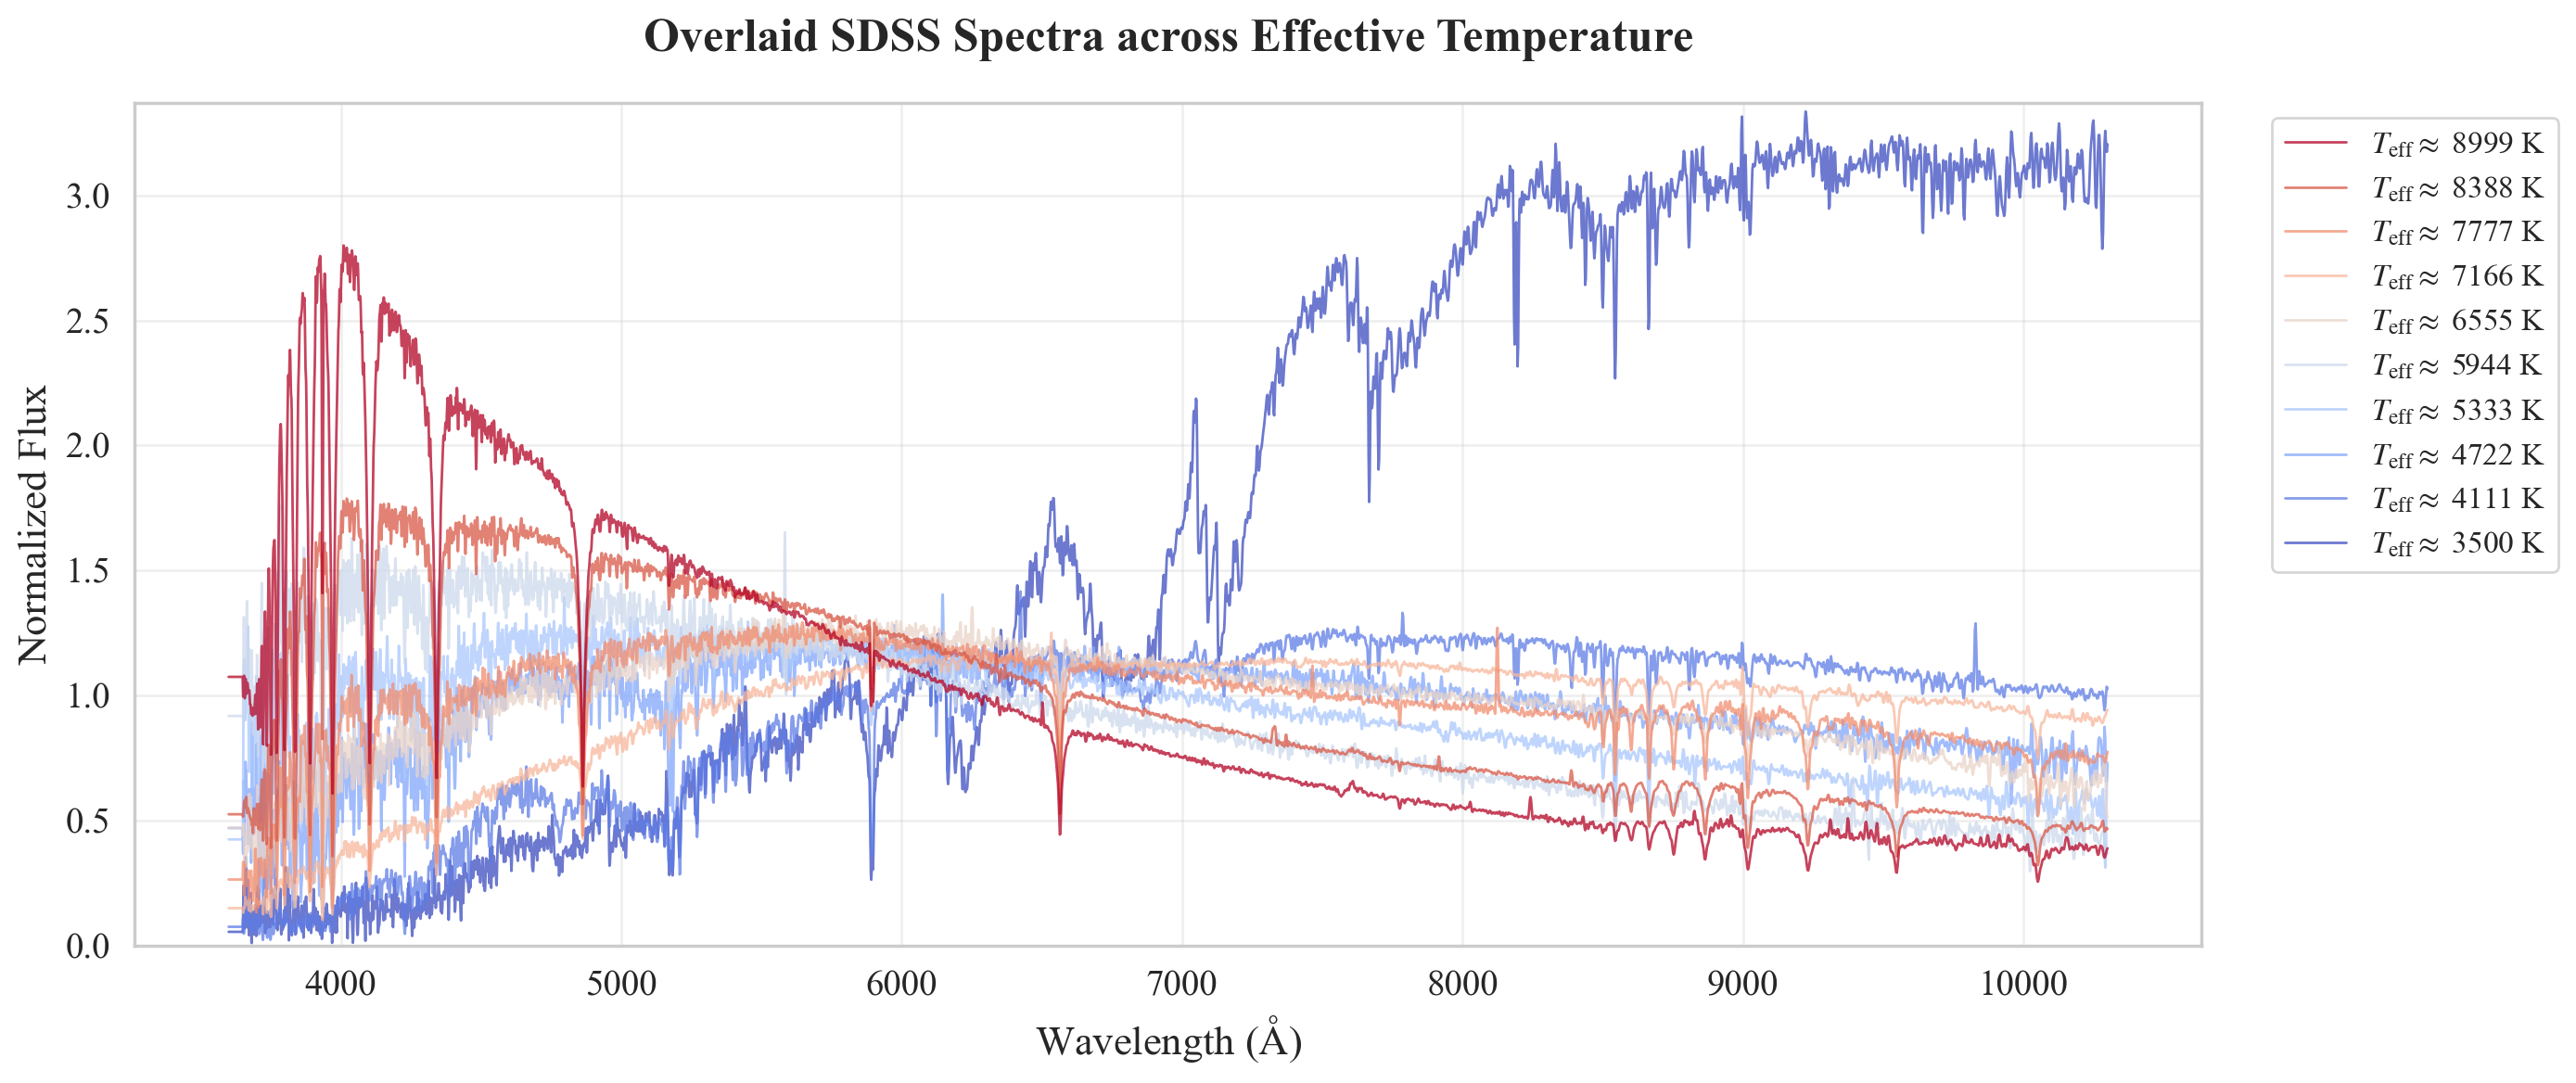

In [7]:
df = pd.read_csv(updated_catalog_path)

t_lo, t_hi = df['teff'].min(), df['teff'].max()
target_teffs = np.linspace(t_lo, t_hi, 10)

selected_indices, actual_teffs = [], []
for target in target_teffs:
    idx = int((df['teff'] - target).abs().idxmin())
    selected_indices.append(idx)
    actual_teffs.append(float(df.loc[idx, 'teff']))

plt.figure(figsize=(14, 6), dpi=200)
all_flux = []
with h5py.File(master_h5_path, 'r') as h5f:
    for i, idx in enumerate(selected_indices):
        flux = h5f['X'][idx].ravel()
        color = plt.cm.coolwarm((actual_teffs[i] - t_lo) / (t_hi - t_lo))
        plt.plot(standard_wave, flux, linewidth=1.0, alpha=0.75, color=color,
                 label=rf"$T_{{\rm eff}} \approx$ {actual_teffs[i]:.0f} K")
        all_flux.append(flux)

all_flux = np.concatenate(all_flux)
plt.xlabel(r"Wavelength ($\mathrm{\AA}$)", fontsize=16)
plt.ylabel("Normalized Flux", fontsize=16)
plt.title("Overlaid SDSS Spectra across Effective Temperature", fontsize=18, fontweight='bold', pad=20)
plt.xticks(fontsize=14); plt.yticks(fontsize=14)
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[::-1], labels[::-1], loc='upper right', bbox_to_anchor=(1.18, 1), fontsize=12)
plt.ylim(0, np.percentile(all_flux, 99.9) * 1.05)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2.6 Label distribution consistency across splits

Violin plots of the Teff distribution in each partition. With quantile stratification the three shapes should be indistinguishable; the accompanying table reports the per-decile counts so that agreement in the sparse hot tail, where the violin is too thin to read, can be checked numerically.

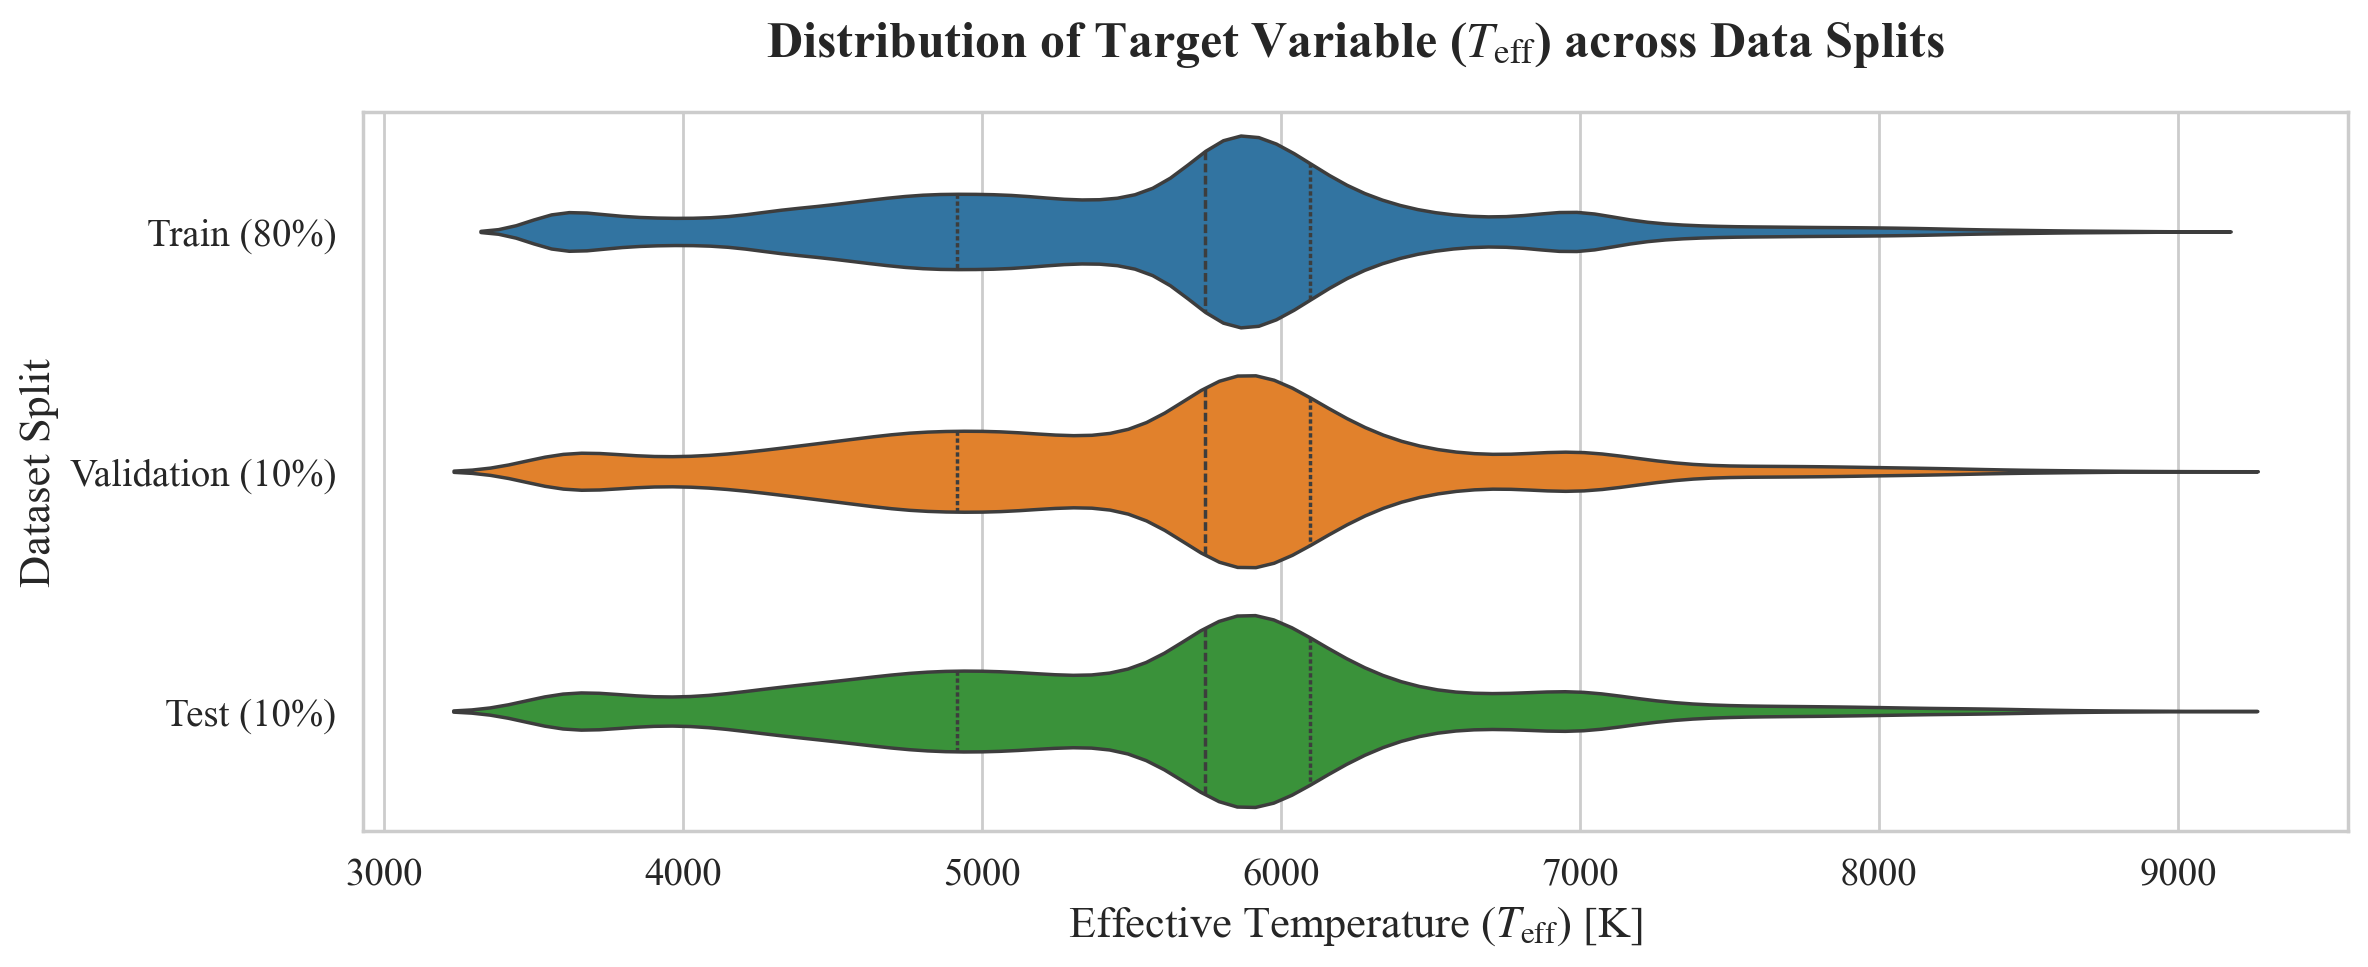

Per-decile share of each partition (%):


dataset_split,train,val,test,max_dev_pp
teff,,,,
"(3500.015, 4277.806]",10.0,10.0,10.0,0.0
"(4277.806, 4744.071]",10.0,10.0,10.0,0.0
"(4744.071, 5090.507]",10.0,10.0,10.0,0.0
"(5090.507, 5486.207]",10.0,10.0,10.0,0.0
"(5486.207, 5745.166]",10.0,10.0,10.0,0.0
"(5745.166, 5876.851]",10.0,10.0,10.0,0.0
"(5876.851, 6012.612]",10.0,10.0,10.0,0.0
"(6012.612, 6213.797]",10.0,10.0,10.0,0.0
"(6213.797, 6795.676]",10.0,10.0,10.0,0.0


Largest deviation between partitions: 0.00 percentage points


In [8]:
df = pd.read_csv(updated_catalog_path)

fig, ax = plt.subplots(figsize=(12, 5), dpi=200)
sns.violinplot(
    data=df, x='teff', y='dataset_split', order=['train', 'val', 'test'],
    hue='dataset_split', hue_order=['train', 'val', 'test'], legend=False,
    palette=['#1f77b4', '#ff7f0e', '#2ca02c'],
    inner='quartile', orient='h', density_norm='width', ax=ax)

ax.set_xlabel(r"Effective Temperature ($T_{\mathrm{eff}}$) [K]", fontsize=16)
ax.set_ylabel("Dataset Split", fontsize=16)
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(['Train (80%)', 'Validation (10%)', 'Test (10%)'], fontsize=14)
ax.tick_params(axis='x', labelsize=14)
ax.set_title(r"Distribution of Target Variable ($T_{\mathrm{eff}}$) across Data Splits", fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# --- numerical parity check ---------------------------------------------------
edges = np.percentile(df['teff'], np.arange(0, 101, 10))
edges[-1] += 1e-6
bins = pd.cut(df['teff'], bins=edges, include_lowest=True)
tab = pd.crosstab(bins, df['dataset_split'], normalize='columns') * 100
tab = tab[['train', 'val', 'test']].round(2)
tab['max_dev_pp'] = (tab.max(axis=1) - tab.min(axis=1)).round(2)
print("Per-decile share of each partition (%):")
display(tab)
print(f"Largest deviation between partitions: "
      f"{tab['max_dev_pp'].max():.2f} percentage points")

In [9]:
from scipy.stats import ks_2samp

tr = df.loc[df.dataset_split == 'train', 'teff'].values
print(f"{'split':>6} {'n':>8} {'KS D':>8} {'p':>8}")
for s in ['val', 'test']:
    o = df.loc[df.dataset_split == s, 'teff'].values
    k = ks_2samp(tr, o)
    print(f"{s:>6} {len(o):>8,} {k.statistic:>8.4f} {k.pvalue:>8.3f}")

 split        n     KS D        p
   val   18,898   0.0025    1.000
  test   18,898   0.0029    0.999


## 2.7 Where the unusable pixels lie

A short diagnostic on 50 catalogue files. It counts, in 25 Å bins, how many files carry an unusable pixel (non-finite, non-positive or zero inverse variance) at that wavelength, and lists the bins affected in at least half of them. These are the stretches that Section 2.2 bridges by interpolation in almost every spectrum, notably the blue edge of the grid.

In [10]:
from collections import Counter
rng = np.random.default_rng(0)
probe = golden_df.sample(50, random_state=0)

bad_counter = Counter()
for _, row in probe.iterrows():
    fp = get_sdss_filename(row, root_dir)
    if not os.path.exists(fp):
        continue
    wave, flux, ivar, _ = read_sdss_spectrum(fp)
    if wave is None:
        continue
    in_range = (wave >= UNIVERSAL_START) & (wave <= UNIVERSAL_END)
    good = np.isfinite(flux) & (flux > 0)
    if ivar is not None:
        good &= np.isfinite(ivar) & (ivar > 0)
    for w in wave[in_range & ~good]:
        bad_counter[int(w // 25) * 25] += 1   # 25 A bins

print(f"{'lambda (A)':>12} {'files affected':>15}")
for lam, c in sorted(bad_counter.items()):
    if c >= 25:            # bad in at least half the probe files
        print(f"{lam:>12} {c:>15} / 50")

  lambda (A)  files affected
        3600            1500 / 50
        3625            1450 / 50
